<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 08: Excitons: diffusion, annihilation and quenching

**Goals.** Measure exciton diffusion with KMC, solve the steady-state exciton continuity equation with
annihilation, and run exciton KMC inside a device box.

### Theory
$D=\frac16\sum_jk_jr_j^2$ (3D) and $L_D=\sqrt{D\tau}$. Continuum steady state:
$D n''-n/\tau-\gamma_{TT}n^2-k_{SP}n\,p+G=0$. In KMC, TTA appears as a pair rate $k_{TT}(R_{TT}/r)^6$
and TPQ as a quenching rate set by nearby polarons.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


In [2]:
from orchid.lattice import Lattice
from orchid.exciton import exciton_kmc
for s in (0.0, 0.05, 0.1):
    lat = Lattice(30, a=1.6e-9, seed=1).set_disorder(max(s, 1e-6))
    r = exciton_kmc(lat, 300.0, tau=1e-9, R0=2.0, n_excitons=4000)
    print(f"sigma={s:.2f} eV: D = {r['D']:.2e} m^2/s, L_D = {r['L_D']*1e9:.1f} nm")

sigma=0.00 eV: D = 2.69e-07 m^2/s, L_D = 16.4 nm
sigma=0.05 eV: D = 4.09e-08 m^2/s, L_D = 6.4 nm


sigma=0.10 eV: D = 7.66e-09 m^2/s, L_D = 2.8 nm


Energetic disorder traps excitons in low-energy sites and shortens $L_D$ (V7).

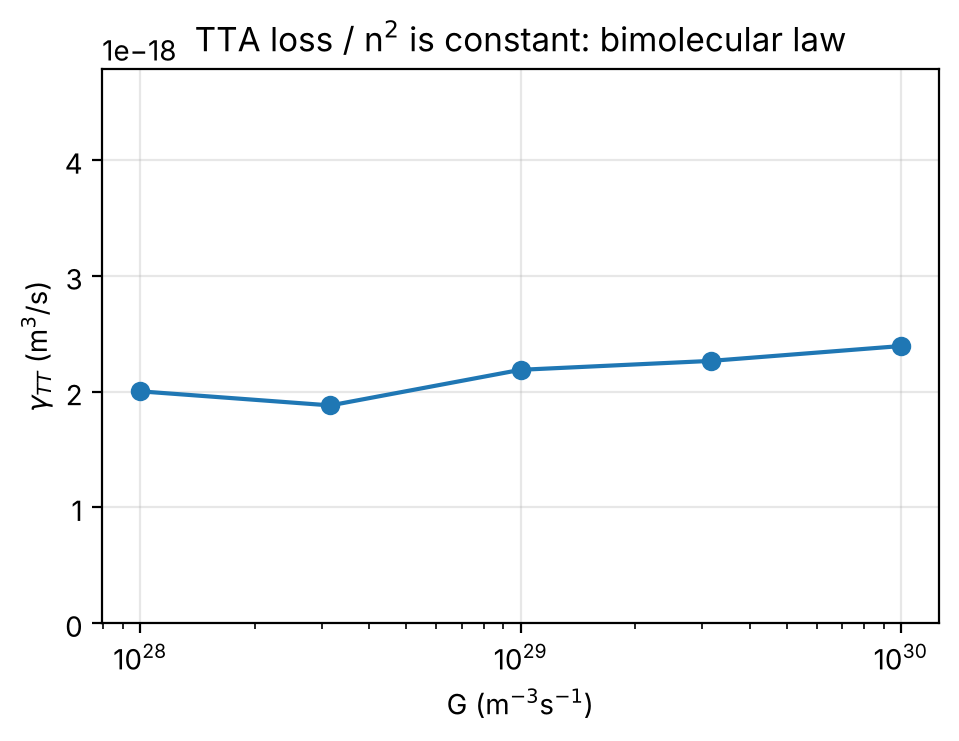

In [3]:
from orchid.exciton_device import ExcitonDeviceKMC
Gs = np.logspace(28, 30, 5)
gam = []
for G in Gs:
    x = ExcitonDeviceKMC((16, 16, 16), tau_r=1e-6, tau_nr=4e-6, R0=1.5, periodic_z=True, k_TT0=1e8, R_TT=1.5)
    r = x.run(G, n_events=150000, n_eq=50000)
    gam.append(r["frac_TTA"] * G / r["n_ex"]**2)
plt.semilogx(Gs, gam, "o-"); plt.xlabel(r"G (m$^{-3}$s$^{-1}$)"); plt.ylabel(r"$\gamma_{TT}$ (m$^3$/s)")
plt.ylim(0, 2 * max(gam)); plt.title("TTA loss / n$^2$ is constant: bimolecular law");

**Exercise.** Set `tau_nr` very large and all annihilation to zero. What should `eta_rad` be?

<details><summary>Solution</summary>

1, because every exciton then decays radiatively. In general $\eta_{rad}=k_r/(k_r+k_{nr})$, and V24 checks this limit in the full device.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("08", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 08`.

In [4]:
from orchid.tutorials import quiz
quiz("08")

Quiz 08: Excitons: diffusion, annihilation and quenching

Q1. In 3D, the exciton diffusion coefficient from KMC rates k_j to neighbours at r_j is
    (a) D = sum k_j r_j / 3
    (b) D = sum k_j r_j^2
    (c) D = sum k_j r_j^2 / 6
    (d) D = 1 / (6 tau)

Q2. The exciton diffusion length is
    (a) L_D = D tau
    (b) L_D = D / tau
    (c) L_D = sqrt(6 D tau)
    (d) L_D = sqrt(D tau)

Q3. At high exciton density, triplet-triplet annihilation adds which loss term to the continuity equation?
    (a) -gamma n p
    (b) -k n
    (c) -n / tau
    (d) -gamma_TT n^2

Q4. For a purely fluorescent emitter, spin statistics limit the singlet fraction to
    (a) 25 %
    (b) 75 %
    (c) 50 %
    (d) 100 %

Q5. Why does EQE roll off at high current in OLEDs?
    (a) Bimolecular quenching (TTA, exciton-polaron quenching TPQ) grows faster than the generation
    (b) The emission wavelength shifts
    (c) Charge balance always improves
    (d) Outcoupling drops

Answer with quiz("08", answers="....."

In [5]:
# replace with your answers, e.g. "abcda"
# quiz("08", answers=".....")

<details><summary>Answer key</summary>

`cddaa`. Run `quiz("08", answers="cddaa")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`